In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
data = pd.read_csv("../data/course_lead_scoring_2026.csv")

In [4]:
df = pd.DataFrame(data)

In [5]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [6]:
numerical_cols = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']
numerical_cols

['annual_income',
 'number_of_courses_viewed',
 'interaction_count',
 'lead_score']

In [7]:
df.columns = df.columns.str.lower().str.replace(' ', '_')
categorical_cols = list(df.dtypes[df.dtypes == 'str'].index)

for c in categorical_cols:
    df[c] = df[c].str.lower().str.replace(' ', '_').fillna('NA')

for n in numerical_cols:
    df[n] = df[n].fillna(0.0)

In [8]:
categorical_cols

['lead_source', 'industry', 'employment_status', 'location']

In [9]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [10]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [11]:
df.isnull().sum()

lead_source                 0
industry                    0
employment_status           0
location                    0
annual_income               0
number_of_courses_viewed    0
interaction_count           0
lead_score                  0
converted                   0
dtype: int64

In [12]:
df['industry'].mode()

0    technology
Name: industry, dtype: str

## Q1: technology

In [13]:
df[numerical_cols].corr()

,annual_income,number_of_courses_viewed,interaction_count,lead_score
annual_income,1.000000,0.161300,0.122842,0.229496
number_of_courses_viewed,0.161300,1.000000,0.721609,0.757204
interaction_count,0.122842,0.721609,1.000000,0.915746
lead_score,0.229496,0.757204,0.915746,1.000000


<Axes: >

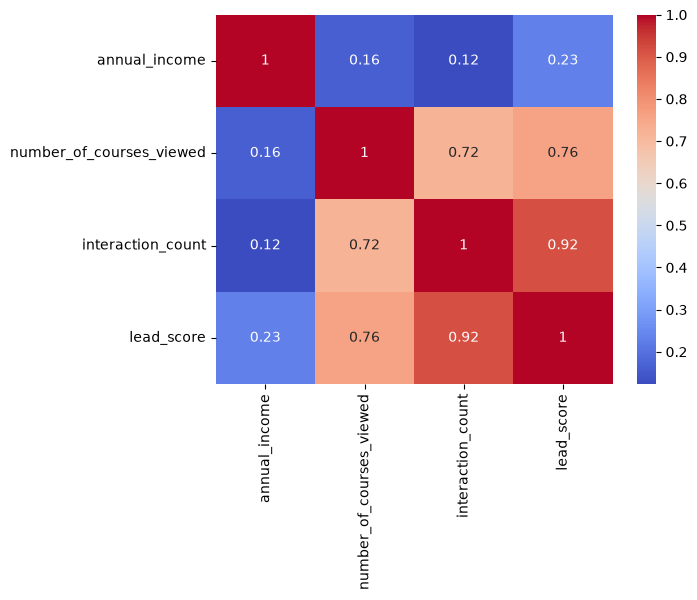

In [14]:
sns.heatmap(df[numerical_cols].corr(), annot=True, cmap='coolwarm')

## Q2: interaction_count and lead_score

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NA,0.0,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NA,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [17]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

In [18]:
y_full_train = df_full_train['converted'].values
y_test = df_test['converted'].values
y_train = df_train['converted'].values
y_val = df_val['converted'].values

In [19]:
del df_full_train['converted']
del df_test['converted']
del df_train['converted']
del df_val['converted']

In [20]:
from sklearn.metrics import mutual_info_score

In [21]:
df_train[categorical_cols]

,lead_source,industry,employment_status,location
4702,paid_ads,finance,employed,asia
2155,events,finance,employed,south_america
289,referral,NA,employed,asia
1822,organic_search,finance,employed,north_america
3442,events,technology,employed,north_america
...,...,...,...,...
3200,paid_ads,finance,employed,asia
617,social_media,retail,employed,asia
1992,organic_search,finance,employed,africa
3301,social_media,retail,employed,asia


In [22]:
y_train

array([1, 0, 1, ..., 1, 0, 0], shape=(3000,))

In [23]:
def mutual_info_score_(series):
    return mutual_info_score(series, y_train)

In [24]:
mi = df_train[categorical_cols].apply(mutual_info_score_)
mi.sort_values(ascending=False)

lead_source          0.034346
employment_status    0.018966
industry             0.001995
location             0.001043
dtype: float64

## Q3: lead_source

In [25]:
from sklearn.feature_extraction import DictVectorizer

In [31]:
from sklearn.linear_model import LogisticRegression

In [26]:
dv = DictVectorizer(sparse=False)

In [27]:
train_dicts = df_train.to_dict(orient='records')

In [28]:
X_train = dv.fit_transform(train_dicts)

In [32]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000, random_state=42)

In [35]:
model.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary <random_state>` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The 

In [37]:
val_dicts = df_val.to_dict(orient='records')

In [38]:
X_val = dv.transform(val_dicts)

In [39]:
y_pred = model.predict(X_val)

In [42]:
(y_pred == y_val).mean()

np.float64(0.645)

In [43]:
from sklearn.metrics import accuracy_score

In [44]:
accuracy_score(y_pred, y_val)

0.645

In [46]:
acc = accuracy_score(y_val, y_pred)

In [47]:
round(acc, 2)

0.65

## Q4: 0.65

In [48]:
features = categorical_cols + numerical_cols
original_accuracy = 0.645

for feature in ['lead_source', 'number_of_courses_viewed', 'interaction_count']:
    selected_features = [f for f in features if f != feature]

    train_dicts = df_train[selected_features].to_dict(orient='records')
    val_dicts = df_val[selected_features].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(train_dicts)
    X_val = dv.transform(val_dicts)

    model = LogisticRegression(
        solver='liblinear',
        C=1.0,
        max_iter=1000,
        random_state=42
    )

    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)

    accuracy = accuracy_score(y_val, y_pred)
    difference = original_accuracy - accuracy

    print(feature, accuracy, difference)

lead_source 0.642 0.0030000000000000027
number_of_courses_viewed 0.643 0.0020000000000000018
interaction_count 0.601 0.04400000000000004


## Q5: number_of_courses_viewed

In [49]:
train_dicts = df_train.to_dict(orient='records')
val_dicts = df_val.to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

C = [0.000001, 0.00001, 0.0001, 0.001]
for c in C:
    model = LogisticRegression(
        solver='liblinear',
        C=c,
        max_iter=1000,
        random_state=42
    )
    model.fit(X_train, y_train)
    y_pred = model.predict(X_val)
    acc  = accuracy_score(y_val, y_pred)
    print(c, round(acc, 3))

1e-06 0.598
1e-05 0.598
0.0001 0.613
0.001 0.645


## Q6: 0.001